# Length of stay: Logistic regression

Multinomial logistic regression on standardized numerics plus one-hot categoricals. It is linear in the features, so non-linear effects such as the U-shaped age effect only come through the `age_group` dummies. `max_iter` is raised from 100 so the solver converges; it is not a tuned setting.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000, random_state=utils.SEED)
model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


== Logistic regression ==  macro-F1 0.297  accuracy 0.462
              precision    recall  f1-score   support

     <1 week       0.49      0.82      0.61      4554
   1-4 weeks       0.39      0.18      0.25      3420
  1-3 months       0.39      0.26      0.31      2017
   3+ months       0.33      0.01      0.02       553

    accuracy                           0.46     10544
   macro avg       0.40      0.32      0.30     10544
weighted avg       0.43      0.46      0.40     10544

quadratic weighted kappa: 0.179


train accuracy 0.574  |  fit 14.3s  predict 0.0s


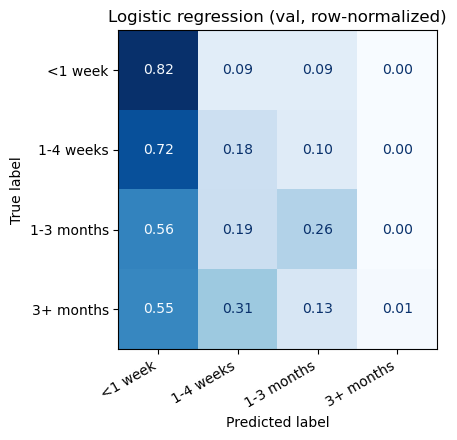

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Logistic regression",
                                           results_dir=RESULTS_DIR)

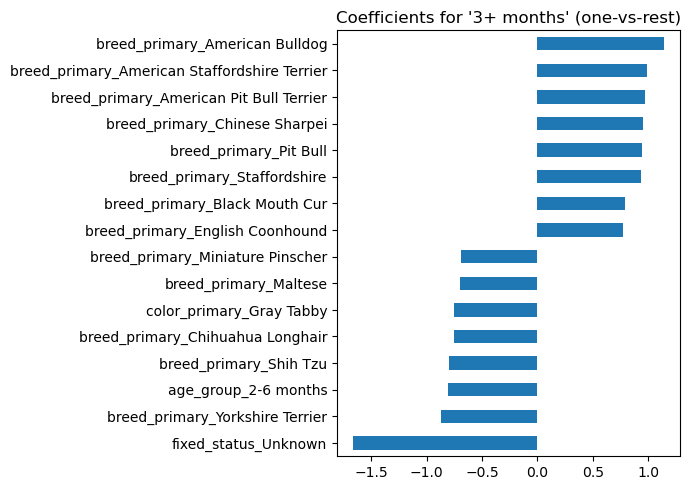

In [4]:
# Largest coefficients for the longest-stay class (features are standardized/one-hot,
# so magnitudes are roughly comparable; associations, not causes)
names = pipe.named_steps["pre"].get_feature_names_out()
model = pipe.named_steps["model"]
coef = pd.DataFrame(model.coef_, index=model.classes_, columns=names).T
top = coef["3+ months"].sort_values()
pd.concat([top.head(8), top.tail(8)]).plot(kind="barh", figsize=(7, 5),
                                           title="Coefficients for '3+ months' (one-vs-rest)")
plt.tight_layout(); plt.show()

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: regularization strength `C` and class weighting. A linear model has few knobs, so expect a small gain, mostly from `class_weight` helping the rare long-stay bins.

In [5]:
from scipy.stats import loguniform

base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'C': loguniform(1e-3, 1e2),           # inverse regularization strength
    'class_weight': [None, 'balanced'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Logistic regression (tuned)", n_iter=12, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Logistic regression (tuned): 12 candidates in 0.4 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.310
best params: {'C': 3.4702669886504163, 'class_weight': 'balanced'}


,C,class_weight,inner_val_f1_macro,mean_fit_time
0,3.470267,balanced,0.309849,20.853845
1,14.528247,balanced,0.309291,23.939560
2,0.046617,balanced,0.308997,11.119404
3,0.008264,balanced,0.307365,8.622367
4,0.008261,balanced,0.306950,7.857232
5,0.001915,balanced,0.297210,5.313436
6,0.001952,balanced,0.297208,5.613573
7,0.001009,balanced,0.287773,4.601354
8,1.143578,None,0.282702,15.776308
9,0.984674,None,0.282157,17.325089


== Logistic regression (tuned) ==  macro-F1 0.360  accuracy 0.385
              precision    recall  f1-score   support

     <1 week       0.64      0.35      0.45      4554
   1-4 weeks       0.45      0.37      0.41      3420
  1-3 months       0.33      0.44      0.38      2017
   3+ months       0.12      0.57      0.20       553

    accuracy                           0.38     10544
   macro avg       0.39      0.43      0.36     10544
weighted avg       0.49      0.38      0.41     10544

quadratic weighted kappa: 0.217


train accuracy 0.445  |  fit 21.5s  predict 0.0s


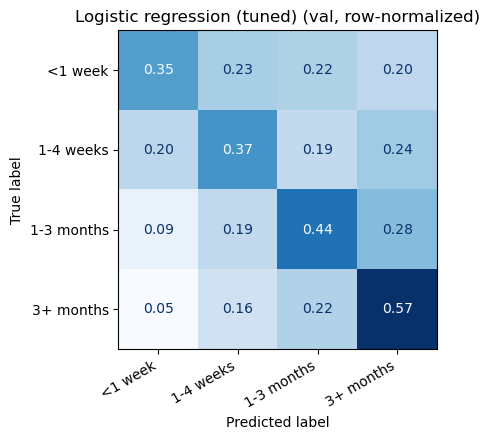

In [6]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Logistic regression (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [7]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Logistic regression,0.462,0.297,0.179,0.574,0.821,0.179,0.256,0.011
Logistic regression (tuned),0.385,0.360,0.217,0.445,0.348,0.370,0.441,0.571
